# 🌊 Comparación de Métodos de Imputación — v2 con Optimización
## MissForest vs XGBoost vs CatBoost | Estación Santander | Gaps ≤ 30 días

---

### Mejoras sobre la versión anterior

| # | Mejora | Justificación |
|---|---|---|
| 1 | **Leads de caudal** (Q_lead1..15) | Válido para reconstrucción bidireccional |
| 2 | **Estacionalidad cíclica** (sin/cos) | Elimina discontinuidad dic→ene |
| 3 | **Precipitación máxima** (P_max7d) | Captura eventos de lluvia intensa |
| 4 | **Optimización de hiperparámetros** | `RandomizedSearchCV` + `TimeSeriesSplit` — UNA VEZ |

### Modelos comparados
| Modelo | Tipo | Referencia |
|---|---|---|
| **MissForest** | Bagging (RF) | Arriagada et al. (2021) |
| **XGBoost** | Boosting gradiente | Magyari-Sáska et al. (2025) |
| **CatBoost** | Boosting ordenado | Magyari-Sáska et al. (2025)|
| **LGM** | LightGBM con optimización de hiperparámetros |Szczepanek, R. (2022) |


### ⚡ Tiempo estimado total: ~35-45 minutos
- Optimización : ~10-12 min (una sola vez)
- Validación   : ~20-25 min (parámetros fijos)
- Reconstrucción: ~3-5 min

### Referencias
1. **Magyari-Sáska et al. (2025)** — *Applied Sciences*, 15(3), 1242. https://doi.org/10.3390/app15031242
2. **Arriagada et al. (2021)** — *Journal of Hydrology*. https://doi.org/10.1016/j.jhydrol.2021.126499
3. **Kashinath et al. (2023)** — *Hydrology*, 10(4), 95. https://doi.org/10.3390/hydrology10040095
4. **Szczepanek, R. (2022)** Daily Streamflow Forecasting in Mountainous Catchment Using XGBoost, LightGBM and CatBoost. Hydrology, 9(12), 226. https://doi.org/10.3390/hydrology9120226

## 📦 PASO 1 — Importaciones

In [1]:
# import sys
# !{sys.executable} -m pip install xgboost catboost hydroeval tqdm

import sys
!{sys.executable} -m pip install xgboost catboost hydroeval tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import plotly.graph_objects as go
import warnings, time
warnings.filterwarnings('ignore')

from tqdm.notebook import tqdm

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor   # MissForest
from xgboost import XGBRegressor                    # XGBoost
from catboost import CatBoostRegressor              # CatBoost
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from lightgbm import LGBMRegressor
import hydroeval as he

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

import sklearn, xgboost, catboost
print('✅ Librerías cargadas')
print(f'   scikit-learn: {sklearn.__version__}')
print(f'   xgboost     : {xgboost.__version__}')
print(f'   catboost    : {catboost.__version__}')

✅ Librerías cargadas
   scikit-learn: 1.5.1
   xgboost     : 3.2.0
   catboost    : 1.2.10


In [2]:
df_santander = pd.read_excel(
    '../datos/entrada/Santander_Quilichao_variables_Cenicana_IDEAM.xlsx',
    sheet_name='Data'
)

In [3]:
df_santander.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4365 entries, 0 to 4364
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   nm_ema         4365 non-null   object        
 1   fc_obsrvcion   4365 non-null   object        
 2   Año            4365 non-null   int64         
 3   Mes            4365 non-null   int64         
 4   Día            4365 non-null   int64         
 5   Fecha_         4365 non-null   datetime64[ns]
 6   Faltantes      4365 non-null   object        
 7   tmp_minma      4364 non-null   float64       
 8   tmp_maxma      4364 non-null   float64       
 9   hmd_rel_minma  4364 non-null   float64       
 10  hmd_rel_maxma  4365 non-null   int64         
 11  tmp_mdia       4365 non-null   object        
 12  hmd_rel_mdia   4365 non-null   object        
 13  prcptcion      4365 non-null   float64       
 14  evp_clclada    4365 non-null   float64       
 15  rdcion_slar    4365 n

## 🗂️ PASO 2 — Carga y preprocesamiento

In [4]:
df_santander['tmp_mdia']     = pd.to_numeric(df_santander['tmp_mdia'],     errors='coerce')
df_santander['hmd_rel_mdia'] = pd.to_numeric(df_santander['hmd_rel_mdia'], errors='coerce')

# ── Imputación variables explicativas (promedio histórico) ────────────────────
def imputar_promedio_historico(df, columna):
    """Imputa con promedio del mismo día calendario en años anteriores.
    Preserva la estructura estacional sin introducir información futura."""
    df = df.sort_values('Fecha_').copy()
    df['ph'] = df.groupby(['Mes', 'Día'])[columna].transform(
        lambda x: x.shift().expanding().mean()
    )
    df[columna] = df[columna].fillna(df['ph'])
    return df.drop(columns=['ph'])

df_imputado = df_santander.copy()
for col in ['tmp_minma','tmp_maxma', 'tmp_mdia', 'hmd_rel_minma', 'hmd_rel_mdia']:
    df_imputado = imputar_promedio_historico(df_imputado, col)

print(f'Dataset: {df_santander.shape[0]} filas × {df_santander.shape[1]} columnas')
print(f'Caudal faltante: {df_santander["m^3/s"].isna().sum()} '
      f'({df_santander["m^3/s"].isna().mean()*100:.1f}%)')

Dataset: 4365 filas × 17 columnas
Caudal faltante: 1641 (37.6%)


### % de Valores faltantes respecto del total de datos del dataset Buga🎯

In [5]:
tabla_faltantes = pd.DataFrame({
    'Faltantes': df_imputado.isnull().sum(),
    '% Faltantes': (df_imputado.isnull().sum() / len(df_santander)) * 100
})

tabla_faltantes = tabla_faltantes.sort_values(by='% Faltantes', ascending=False)

tabla_faltantes

,Faltantes,% Faltantes
m^3/s,1641,37.594502
hmd_rel_minma,0,0.000000
rdcion_slar,0,0.000000
evp_clclada,0,0.000000
prcptcion,0,0.000000
hmd_rel_mdia,0,0.000000
tmp_mdia,0,0.000000
hmd_rel_maxma,0,0.000000
nm_ema,0,0.000000
fc_obsrvcion,0,0.000000


## ⚙️ PASO 3 — Feature engineering con las 3 mejoras

### Mejora 1: Leads de caudal
Para gaps ≤ 30 días siempre existe un dato observado posterior al gap,
por lo que `Q_lead1 = shift(-1)` tiene valores reales y no NaN.
Esto es metodológicamente correcto para **reconstrucción**, no predicción.

### Mejora 2: Estacionalidad cíclica
`mes = 12` y `mes = 1` son meses consecutivos pero en encoding lineal
el modelo los ve como muy distantes (12 vs 1). La codificación
seno/coseno los representa como vecinos en el espacio circular.

"La estacionalidad fue codificada mediante funciones trigonométricas seno y coseno con período anual — denominada Annual Fourier Time encoding — en lugar del encoding lineal ordinario del mes. Esta decisión se fundamenta en que el encoding lineal asigna valores numéricos 1 y 12 a enero y diciembre respectivamente, generando una discontinuidad artificial de magnitud 11 entre meses consecutivos en el calendario hidrológico. La proyección circular sin(2π·mes/12) y cos(2π·mes/12) preserva la continuidad temporal: la distancia euclidiana entre diciembre y enero en el espacio (sin, cos) es 0.52, equivalente a la distancia entre cualquier par de meses consecutivos. He et al. (2025) demostraron que esta codificación produce las mejoras más significativas en predicción de caudal diario sobre 671 cuencas hidrológicas, superando al encoding lineal y a modelos de fundación de propósito general."

https://agupubs.onlinelibrary.wiley.com/doi/10.1029/2020ms002203


### Mejora 3: Precipitación máxima en ventana 7 días
`P_max7d = rolling(7).max()` detecta eventos de lluvia intensa
que el promedio rolling suaviza. Los picos de caudal están
frecuentemente precedidos por un día de lluvia muy alta, no
por lluvias moderadas sostenidas.

In [6]:
df_model = df_imputado.copy()
df_model = df_model.sort_values('Fecha_').set_index('Fecha_')

# ── Lags de precipitación (valores anteriores) ─────────────────────────────────────────────────────
for lag in [1, 2, 3]:
    df_model[f'P_lag{lag}'] = df_model['prcptcion'].shift(lag)

# ── Ventanas acumuladas de precipitación ──────────────────────────────────────
for v in [3, 7, 15, 30]:
    df_model[f'P_{v}d'] = df_model['prcptcion'].rolling(v).sum()

# ── MEJORA 3: Precipitación máxima en ventana de 7 días ───────────────────────
# Captura eventos de lluvia intensa que el promedio rolling suaviza
# Los picos de caudal son precedidos por días de lluvia muy alta
df_model['P_max7d'] = df_model['prcptcion'].rolling(7).max()

# ── Lags de caudal (información del pasado) ───────────────────────────────────
for lag in [1, 2, 3, 7, 15, 30]:
    df_model[f'Q_lag{lag}'] = df_model['m^3/s'].shift(lag)

    #El caudal tiene alta autocorrelación: el caudal de mañana se parece mucho al de hoy. 
    # Los lags 1, 2, 3, 7, 15 y 30 capturan esa memoria hidrológica a diferentes escalas temporales.

# ── MEJORA 1: Leads de caudal (información del futuro) ────────────────────────
# shift(-n): toma el valor n días ADELANTE en la serie
# Para gaps ≤ 30 días estos valores son datos reales observados
# Referencia: válido para reconstrucción porque el 'futuro' del gap ya ocurrió
for lead in [1, 2, 3, 7, 15]:
    df_model[f'Q_lead{lead}'] = df_model['m^3/s'].shift(-lead)

# ── Leads de precipitación ────────────────────────────────────────────────────
for lead in [1, 2, 3]:
    df_model[f'P_lead{lead}'] = df_model['prcptcion'].shift(-lead)

# ── Interacción y evento ──────────────────────────────────────────────────────
df_model['P_x_Qlag1']    = df_model['prcptcion'] * df_model['Q_lag1']
df_model['evento_lluvia'] = (df_model['prcptcion'] > 10).astype(int)

# ── MEJORA 2: Estacionalidad cíclica (seno/coseno) ───────────────────────────
# Reemplaza mes y dia_año lineales que tienen discontinuidad dic→ene
# La codificación circular preserva la continuidad temporal
df_model['mes_sin'] = np.sin(2 * np.pi * df_model.index.month / 12)
df_model['mes_cos'] = np.cos(2 * np.pi * df_model.index.month / 12)
df_model['dia_sin'] = np.sin(2 * np.pi * df_model.index.dayofyear / 365)
df_model['dia_cos'] = np.cos(2 * np.pi * df_model.index.dayofyear / 365)

#Proyecta el ciclo anual sobre el círculo unitario. Diciembre (mes 12) y enero (mes 1) quedan a distancia 0.52 en 
#el espacio circular, no a distancia 11 como en el encoding lineal. Los modelos de árboles no pueden hacer condiciones 
# OR en una sola división, por lo que sin esta transformación necesitarían profundidad adicional para capturar que dic-ene 
# son meses consecutivos.

# ── Transformación logarítmica del target ─────────────────────────────────────
# log1p estabiliza la varianza: evita que los picos dominen el entrenamiento
df_model['Q_log'] = np.log1p(df_model['m^3/s'])

#log1p(x) = log(1+x) evita problemas con caudal = 0. Comprime la distribución sesgada del caudal: 
# los picos de 40 m³/s dejan de dominar el entrenamiento frente a los caudales base de 3 m³/s. 
# Las métricas se calculan con expm1() para volver a m³/s.

# Eliminar filas con NaN en features base (primeras filas por los lags)
df_model = df_model.dropna(subset=[
    'P_lag1', 'P_lag2', 'P_lag3',
    'P_3d', 'P_7d', 'P_15d', 'P_30d',
    'mes_sin', 'mes_cos', 'dia_sin', 'dia_cos'
])

print(f'Dataset de modelado: {df_model.shape[0]} filas')
print(f'  Caudal observado    : {df_model["Q_log"].notna().sum()}')
print(f'  Caudal a reconstruir: {df_model["Q_log"].isna().sum()}')
print(f'\nFeatures por tipo:')
print(f'  Clima               : 4')
print(f'  Precipitación + lags: {len([c for c in df_model.columns if "P_" in c and "lead" not in c])}')
print(f'  Lags de caudal      : {len([c for c in df_model.columns if "Q_lag" in c])}')
print(f'  Leads de caudal     : {len([c for c in df_model.columns if "Q_lead" in c])} ← MEJORA 1')
print(f'  Estacionalidad cícl.: 4 (sin/cos) ← MEJORA 2')
print(f'  P_max7d             : 1 ← MEJORA 3')

Dataset de modelado: 4336 filas
  Caudal observado    : 2695
  Caudal a reconstruir: 1641

Features por tipo:
  Clima               : 4
  Precipitación + lags: 9
  Lags de caudal      : 6
  Leads de caudal     : 5 ← MEJORA 1
  Estacionalidad cícl.: 4 (sin/cos) ← MEJORA 2
  P_max7d             : 1 ← MEJORA 3


In [7]:
df_model.head()

,nm_ema,fc_obsrvcion,Año,Mes,Día,Faltantes,tmp_minma,tmp_maxma,hmd_rel_minma,hmd_rel_maxma,...,P_lead1,P_lead2,P_lead3,P_x_Qlag1,evento_lluvia,mes_sin,mes_cos,dia_sin,dia_cos,Q_log
Fecha_,,,,,,,,,,,,,,,,,,,,,
2010-02-01,Santander de Quilichao,2010-02-01,2010,2,1,Ok,16.2,33.5,30.0,99,...,0.0,0.0,0.0,0.0000,0,0.866025,0.5,0.523416,0.852078,1.190888
2010-02-02,Santander de Quilichao,2010-02-02,2010,2,2,Ok,17.3,33.0,31.0,98,...,0.0,0.0,9.2,0.0000,0,0.866025,0.5,0.538005,0.842942,1.164088
2010-02-03,Santander de Quilichao,2010-02-03,2010,2,3,Ok,19.1,32.8,33.0,96,...,0.0,9.2,0.2,0.0000,0,0.866025,0.5,0.552435,0.833556,1.156881
2010-02-04,Santander de Quilichao,2010-02-04,2010,2,4,Ok,17.7,32.5,32.0,98,...,9.2,0.2,19.4,0.0000,0,0.866025,0.5,0.566702,0.823923,1.136550
2010-02-05,Santander de Quilichao,2010-02-05,2010,2,5,2,19.8,33.5,30.0,95,...,0.2,19.4,1.6,19.4672,0,0.866025,0.5,0.580800,0.814046,1.124605


In [8]:
#df_model['Caudal (m^3/s)'].mean()

In [9]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4336 entries, 2010-02-01 to 2021-12-31
Data columns (total 45 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   nm_ema         4336 non-null   object 
 1   fc_obsrvcion   4336 non-null   object 
 2   Año            4336 non-null   int64  
 3   Mes            4336 non-null   int64  
 4   Día            4336 non-null   int64  
 5   Faltantes      4336 non-null   object 
 6   tmp_minma      4336 non-null   float64
 7   tmp_maxma      4336 non-null   float64
 8   hmd_rel_minma  4336 non-null   float64
 9   hmd_rel_maxma  4336 non-null   int64  
 10  tmp_mdia       4336 non-null   float64
 11  hmd_rel_mdia   4336 non-null   float64
 12  prcptcion      4336 non-null   float64
 13  evp_clclada    4336 non-null   float64
 14  rdcion_slar    4336 non-null   float64
 15  m^3/s          2695 non-null   float64
 16  P_lag1         4336 non-null   float64
 17  P_lag2         4336 non-null   flo

In [10]:
TARGET = 'Q_log'

variables = [
    # Clima
    'tmp_mdia', 'hmd_rel_mdia', 'evp_clclada', 'rdcion_slar',
    # Precipitación — pasado
    'prcptcion', 'P_lag1', 'P_lag2', 'P_3d', 'P_7d', 'P_30d',
    # MEJORA 3: precipitación máxima
    'P_max7d',
    # Precipitación — futuro
    'P_lead1', 'P_lead2', 'P_lead3',
    # Caudal — lags (pasado)
    'Q_lag1', 'Q_lag2', 'Q_lag3', 'Q_lag7', 'Q_lag15', 'Q_lag30',
    # MEJORA 1: caudal — leads (futuro)
    'Q_lead1', 'Q_lead2', 'Q_lead3', 'Q_lead7', 'Q_lead15',
    # Interacción
    'P_x_Qlag1', 'evento_lluvia',
    # MEJORA 2: estacionalidad cíclica
    'mes_sin', 'mes_cos', 'dia_sin', 'dia_cos'
]

df_full = df_model[variables + [TARGET]].copy()
df_obs  = df_full[df_full[TARGET].notna()].copy()

print(f'Total features: {len(variables)}')
print(f'  Versión anterior: ~20 features')
print(f'  Versión actual  : {len(variables)} features (+{len(variables)-20} mejoras)')
print(f'Filas observadas para validación: {len(df_obs)}')

Total features: 31
  Versión anterior: ~20 features
  Versión actual  : 31 features (+11 mejoras)
Filas observadas para validación: 2695


## 🤖 PASO 4 — Optimización de hiperparámetros (una sola vez)

### ¿Por qué optimizar?
Sin optimización los parámetros son elegidos 'a mano' y pueden no ser
óptimos para tu serie específica. Con optimización el modelo aprende
qué configuración minimiza el error **en tus datos**.

### Estrategia — RandomizedSearchCV con TimeSeriesSplit
```
ETAPA 1 — Optimización (una vez, ~8-12 min):
  RandomizedSearchCV(n_iter=15) × TimeSeriesSplit(3 folds)
  → Encuentra los mejores parámetros para cada modelo
  → Se hace UNA VEZ sobre los datos observados

ETAPA 2 — Validación (20-25 min):
  Los parámetros óptimos se usan en TODAS las máscaras
  → Sin re-optimizar en cada iteración
  → La comparación entre modelos es justa Y optimizada
```

**Referencia:** Kashinath et al. (2023) usó `RandomizedSearchCV` con
`TimeSeriesSplit` para optimizar RF en reconstrucción de caudal mensual.
El mismo enfoque se aplica aquí a los 3 modelos.

**⚡ Tiempo total estimado: ~30-40 minutos**

In [11]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.gaussian_process import GaussianProcessRegressor                # ← NUEVO
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern       # ← NUEVO

def crear_imputer(estimador, max_iter=5):
    """IterativeImputer con el estimador dado."""
    return IterativeImputer(estimator=estimador, max_iter=max_iter,
                            random_state=42)

# ── NSE como scorer para la optimización ─────────────────────────────────────
from sklearn.metrics import make_scorer

def nse_scorer_fn(y_true, y_pred):
    obs  = np.expm1(np.array(y_true,  dtype=float))
    pred = np.maximum(np.expm1(np.array(y_pred, dtype=float)), 0)
    denom = np.sum((obs - np.mean(obs))**2)
    return np.nan if denom < 1e-10 else 1 - np.sum((obs-pred)**2)/denom

nse_score = make_scorer(nse_scorer_fn, greater_is_better=True)

# ── Espacios de búsqueda de hiperparámetros ───────────────────────────────────
tscv = TimeSeriesSplit(n_splits=3)

espacios = {
    # ── MissForest (RF) ───────────────────────────────────────────────────────
    'MissForest': {
        'estimator': RandomForestRegressor(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators':     [100, 200, 300],
            'max_depth':        [10, 15, 20, None],
            'max_leaf_nodes':   [50, 100, 200],
            'min_samples_leaf': [1, 3, 5],
            'max_features':     ['sqrt', 'log2']
        }
    },
    # ── XGBoost ───────────────────────────────────────────────────────────────
    'XGBoost': {
        'estimator': XGBRegressor(
            random_state=42, n_jobs=-1, verbosity=0,
            objective='reg:squarederror'
        ),
        'params': {
            'n_estimators':     [100, 200, 300],
            'max_depth':        [4, 6, 8],
            'learning_rate':    [0.05, 0.1, 0.15],
            'subsample':        [0.7, 0.8, 1.0],
            'colsample_bytree': [0.7, 0.8, 1.0],
            'reg_alpha':        [0, 0.1, 0.5],
            'reg_lambda':       [1, 2, 5]
        }
    },
    # ── CatBoost ──────────────────────────────────────────────────────────────
    'CatBoost': {
        'estimator': CatBoostRegressor(random_seed=42, verbose=0),
        'params': {
            'iterations':    [100, 200, 300],
            'depth':         [4, 6, 8],
            'learning_rate': [0.05, 0.1, 0.15],
            'l2_leaf_reg':   [1, 3, 5, 10]
        }
    },
    # ── LightGBM con optimización de hiperparámetros ──────────────────────────────── ← NUEVO
       'LightGBM': {
    'estimator': LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    'params': {
        'n_estimators':     [200, 400, 600],
        'max_depth':        [6, 8, 10, -1],
        'learning_rate':    [0.03, 0.05, 0.1],
        'num_leaves':       [31, 63, 127],
        'subsample':        [0.7, 0.8, 1.0],
        'colsample_bytree': [0.7, 0.8, 1.0],
        'min_child_samples':[10, 20, 50]
    }
}
    
}

# ── Optimización: UNA SOLA VEZ sobre datos observados ────────────────────────
X_opt = df_obs[variables].values
y_opt = df_obs[TARGET].values

mejores_estimadores = {}
resultados_opt      = {}
t_opt = time.time()

print('🔍 Optimizando hiperparámetros (n_iter=15, TimeSeriesSplit=3)...')
print('   Esto se hace UNA SOLA VEZ — los mejores parámetros se reutilizan')
print('   en todas las máscaras de validación.\n')

for nombre, config in espacios.items():
    print(f'   → Optimizando {nombre}...')
    t_m = time.time()

    search = RandomizedSearchCV(
        estimator=config['estimator'],
        param_distributions=config['params'],
        n_iter=15,
        cv=tscv,
        scoring=nse_score,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )
    search.fit(X_opt, y_opt)

    mejores_estimadores[nombre] = search.best_estimator_
    resultados_opt[nombre] = {
        'mejor_nse':    round(search.best_score_, 4),
        'mejores_params': search.best_params_,
        'tiempo_min':   round((time.time() - t_m) / 60, 1)
    }
    print(f'     NSE_cv = {search.best_score_:.4f} | '
          f'Tiempo: {(time.time()-t_m)/60:.1f} min')

print(f'\n✅ Optimización completada en {(time.time()-t_opt)/60:.1f} minutos')
print('\n📋 Mejores parámetros encontrados:')
for nombre, res in resultados_opt.items():
    print(f'\n  {nombre} (NSE_cv = {res["mejor_nse"]}):')
    for k, v in res['mejores_params'].items():
        print(f'    {k}: {v}')

# ── Construir modelos de validación con parámetros optimizados ────────────────
modelos_val = {
    nombre: crear_imputer(estimador, max_iter=5)
    for nombre, estimador in mejores_estimadores.items()
}

params_finales = mejores_estimadores.copy()

colores = {'MissForest': 'steelblue', 'XGBoost': 'darkorange',
           'CatBoost': 'crimson', 'GP': 'forestgreen'}              # ← NUEVO

print('\n✅ Modelos de validación listos con parámetros optimizados')
print(f'   Total iteraciones validación: {len(modelos_val)} × 3 × 20 '  # ← NUEVO
      f'= {len(modelos_val)*3*20}')

🔍 Optimizando hiperparámetros (n_iter=15, TimeSeriesSplit=3)...
   Esto se hace UNA SOLA VEZ — los mejores parámetros se reutilizan
   en todas las máscaras de validación.

   → Optimizando MissForest...
     NSE_cv = 0.3855 | Tiempo: 0.4 min
   → Optimizando XGBoost...
     NSE_cv = 0.4461 | Tiempo: 0.1 min
   → Optimizando CatBoost...
     NSE_cv = 0.4433 | Tiempo: 0.5 min
   → Optimizando LightGBM...
     NSE_cv = 0.4654 | Tiempo: 0.8 min

✅ Optimización completada en 1.7 minutos

📋 Mejores parámetros encontrados:

  MissForest (NSE_cv = 0.3855):
    n_estimators: 200
    min_samples_leaf: 1
    max_leaf_nodes: 200
    max_features: sqrt
    max_depth: 15

  XGBoost (NSE_cv = 0.4461):
    subsample: 0.8
    reg_lambda: 2
    reg_alpha: 0.1
    n_estimators: 200
    max_depth: 4
    learning_rate: 0.05
    colsample_bytree: 0.8

  CatBoost (NSE_cv = 0.4433):
    learning_rate: 0.1
    l2_leaf_reg: 3
    iterations: 100
    depth: 4

  LightGBM (NSE_cv = 0.4654):
    subsample: 0.7
  

## 📐 PASO 5 — Métricas

Incluye el **Performance Index (PI)** de Magyari-Sáska et al. (2025)
que combina MAE, desviación estándar del error y número de outliers.

In [12]:
def NSE(obs, sim):
    """Nash-Sutcliffe Efficiency. Rango (-∞, 1]. Ideal = 1."""
    obs, sim = np.array(obs, dtype=float), np.array(sim, dtype=float)
    denom = np.sum((obs - np.mean(obs))**2)
    return np.nan if denom < 1e-10 else 1 - np.sum((obs-sim)**2)/denom

def R2(obs, sim):
    """Coeficiente de determinación: cuadrado de la correlación de Pearson.
    Rango [0, 1]. Ideal = 1. Mide la asociación lineal, no el sesgo
    (a diferencia del NSE). Moriasi et al. (2007); Legates y McCabe (1999).
    Nota: sklearn.r2_score = 1 - SSE/SST es matemáticamente igual al NSE."""
    obs, sim = np.array(obs, dtype=float), np.array(sim, dtype=float)
    if np.std(obs) < 1e-10 or np.std(sim) < 1e-10:
        return np.nan
    return float(np.corrcoef(obs, sim)[0, 1] ** 2)

def PBIAS(obs, sim):
    """Porcentaje de sesgo. Ideal = 0. >25% problemático."""
    return 100 * np.sum(obs - sim) / np.sum(obs)

def contar_outliers_tukey(err):
    """Outliers en errores por IQR. Magyari-Sáska et al. (2025)."""
    q1, q3 = np.percentile(err, 25), np.percentile(err, 75)
    iqr = q3 - q1
    return int(np.sum((err < q1 - 1.5*iqr) | (err > q3 + 1.5*iqr)))

def performance_index(mae_v, sd_v, outl_v):
    """PI = 1 - EI. Pesos: W_SD=0.47, W_MAE=0.37, W_EXTR=0.16.
    Magyari-Sáska et al. (2025), ecuaciones 6-9."""
    def norm(v):
        v = np.array(v, dtype=float)
        r = v.max() - v.min()
        return (v - v.min()) / r if r > 0 else np.zeros_like(v)
    return 1 - (0.37*norm(mae_v) + 0.16*norm(outl_v) + 0.47*norm(sd_v))

def calcular_metricas(y_true, y_pred, pct_gap=0):
    """Métricas en escala original m³/s.
    Las métricas se calculan DESPUÉS de deshacer la transformación log1p."""
    obs  = np.expm1(np.array(y_true, dtype=float))
    pred = np.maximum(np.expm1(np.array(y_pred, dtype=float)), 0)
    err  = np.abs(obs - pred)
    kge_val, *_ = he.evaluator(he.kge, pred, obs)
    return {
        'pct_gap':    pct_gap,
        'R²':         round(R2(obs, pred), 4),
        'MAE':        round(mean_absolute_error(obs, pred), 4),
        'RMSE':       round(np.sqrt(mean_squared_error(obs, pred)), 4),
        'NSE':        round(NSE(obs, pred), 4),
        'KGE':        round(float(kge_val), 4),
        'PBIAS':      round(PBIAS(obs, pred), 2),
        'SD_error':   round(float(np.std(err)), 4),
        'N_outliers': contar_outliers_tukey(err)
    }

print('✅ Métricas definidas: R², MAE, RMSE, NSE, KGE, PBIAS, PI')

✅ Métricas definidas: R², MAE, RMSE, NSE, KGE, PBIAS, PI


## 🧪 PASO 6 — Validación con máscaras aleatorias

### Justificación metodológica

La validación con gaps aleatorios del 10–20% es apropiada porque:
1. Los gaps reales a reconstruir (≤30 días) son **dispersos** → misma estructura
2. Diseño exacto de **Magyari-Sáska et al. (2025)** para gaps 5–20%
3. Fuga de información afecta **simétricamente** a todos → comparación válida
4. 20 máscaras/escenario → variabilidad estadística suficiente

Los 3 modelos usan los **parámetros optimizados** del PASO 4.

**⚡ Tiempo estimado: ~20-25 minutos**

In [13]:
PORCENTAJES_GAP = [0.10, 0.15, 0.20]
N_MASCARAS      = 20

total_iter = len(modelos_val) * len(PORCENTAJES_GAP) * N_MASCARAS
print(f'Datos observados para validación: {len(df_obs)}')
print(f'Modelos: {list(modelos_val.keys())}')
print(f'Escenarios: {[f"{int(p*100)}%" for p in PORCENTAJES_GAP]}')
print(f'Máscaras por escenario: {N_MASCARAS}')
print(f'Total iteraciones: {total_iter}')

Datos observados para validación: 2695
Modelos: ['MissForest', 'XGBoost', 'CatBoost', 'LightGBM']
Escenarios: ['10%', '15%', '20%']
Máscaras por escenario: 20
Total iteraciones: 240


In [14]:
resultados = []
t0 = time.time()

pbar = tqdm(total=total_iter, desc='Validando 4 modelos v2', unit='iter')

for pct in PORCENTAJES_GAP:
    for seed in range(N_MASCARAS):

        rng  = np.random.default_rng(seed)
        mask = rng.random(len(df_obs)) < pct
        if mask.sum() < 5:
            pbar.update(len(modelos_val))
            continue

        df_gap = df_obs.copy()
        df_gap.loc[df_gap.index[mask], TARGET] = np.nan
        y_real = df_obs.loc[df_obs.index[mask], TARGET]

        for nombre_modelo, imputer in modelos_val.items():
            try:
                arr    = imputer.fit_transform(df_gap)
                df_imp = pd.DataFrame(arr, columns=df_gap.columns,
                                      index=df_gap.index)
                y_pred = df_imp.loc[df_obs.index[mask], TARGET]

                m = calcular_metricas(y_real, y_pred, pct_gap=int(pct*100))
                m['Modelo'] = nombre_modelo
                m['seed']   = seed
                resultados.append(m)
            except Exception:
                pass

            elapsed = time.time() - t0
            pbar.set_postfix({
                'modelo': nombre_modelo[:8],
                'gap':    f'{int(pct*100)}%',
                'min':    f'{elapsed/60:.1f}'
            })
            pbar.update(1)

pbar.close()
df_res = pd.DataFrame(resultados)
print(f'\n✅ Validación completada en {(time.time()-t0)/60:.1f} minutos')
print(f'   {len(df_res)} evaluaciones exitosas de {total_iter} intentadas')

Validando 4 modelos v2:   0%|          | 0/240 [00:00<?, ?iter/s]


✅ Validación completada en 942.1 minutos
   240 evaluaciones exitosas de 240 intentadas


## 📊 PASO 7 — Resultados de validación

In [15]:
metricas_cols = ['R²', 'MAE', 'RMSE', 'NSE', 'KGE', 'PBIAS']

df_resumen = (
    df_res.groupby(['Modelo', 'pct_gap'])[metricas_cols]
    .agg(['mean', 'std'])
    .round(4)
)

print('\n📋 MÉTRICAS MEDIAS POR MODELO Y ESCENARIO — v2 (3 mejoras)')
print('=' * 70)
print(df_resumen.to_string())
print('=' * 70)

# Interpretación por NSE
print('\n📈 Ranking por NSE medio (todos los escenarios):')
nse_ranking = (
    df_res.groupby('Modelo')['NSE'].mean()
    .sort_values(ascending=False)
)

for modelo, nse in nse_ranking.items():
    if   nse >= 0.75: nivel = '✅ Bueno'
    elif nse >= 0.65: nivel = '🟡 Aceptable'
    elif nse >= 0.50: nivel = '🟠 Moderado'
    else:             nivel = '🔴 Deficiente'
    print(f'  {modelo:12s}: NSE={nse:.4f} → {nivel}')

mejor_modelo_nombre = nse_ranking.index[0]
print(f'\n🏆 Mejor modelo: {mejor_modelo_nombre}')

# Performance Index por modelo
print('\n📊 Performance Index (Magyari-Sáska et al. 2025) — gap 10%:')
sub10 = df_res[df_res['pct_gap']==10].groupby('Modelo')
pi_vals = performance_index(
    sub10['MAE'].mean().values,
    sub10['SD_error'].mean().values,
    sub10['N_outliers'].mean().values
)
for modelo, pi in zip(sub10.groups.keys(), pi_vals):
    print(f'   {modelo:12s}: PI = {pi:.4f}')

# Comparación con v1
print('\n📊 Comparación v1 (sin mejoras) vs v2 (con mejoras) — gap 10%:')
v1 = {'MissForest': 0.4819, 'XGBoost': 0.4577, 'CatBoost': 0.4881}
print(f'   {"Modelo":12s} | {"NSE v1":>8} | {"NSE v2":>8} | {"Δ NSE":>8}')
print(f'   {"-"*12}-+-{"─"*8}-+-{"─"*8}-+-{"─"*8}')
for modelo in ['MissForest', 'XGBoost', 'CatBoost']:
    nse_v2 = df_res[(df_res['Modelo']==modelo)&(df_res['pct_gap']==10)]['NSE'].mean()
    delta  = nse_v2 - v1[modelo]
    print(f'   {modelo:12s} | {v1[modelo]:>8.4f} | {nse_v2:>8.4f} | {delta:>+8.4f}')

df_resumen.to_excel('metricas_3modelos_v2.xlsx')
print('\n✅ Guardado: metricas_3modelos_v2.xlsx')


📋 MÉTRICAS MEDIAS POR MODELO Y ESCENARIO — v2 (3 mejoras)
                        R²             MAE            RMSE             NSE             KGE            PBIAS        
                      mean     std    mean     std    mean     std    mean     std    mean     std     mean     std
Modelo     pct_gap                                                                                                 
CatBoost   10       0.6644  0.0946  1.5636  0.2283  5.0883  1.0845  0.6518  0.0981  0.6580  0.0966   8.1845  4.3099
           15       0.6894  0.0816  1.5581  0.2128  4.9579  1.0062  0.6779  0.0862  0.6851  0.0953   7.4800  4.8382
           20       0.6933  0.0701  1.5405  0.1770  4.9760  0.8419  0.6813  0.0752  0.6853  0.0878   7.8685  4.1400
LightGBM   10       0.6548  0.1086  1.5732  0.2207  5.0859  1.0634  0.6468  0.1101  0.7030  0.1108   5.7930  5.4075
           15       0.6851  0.0767  1.5615  0.1909  4.9447  0.8614  0.6774  0.0791  0.7314  0.0953   5.4955  5.4714
           20

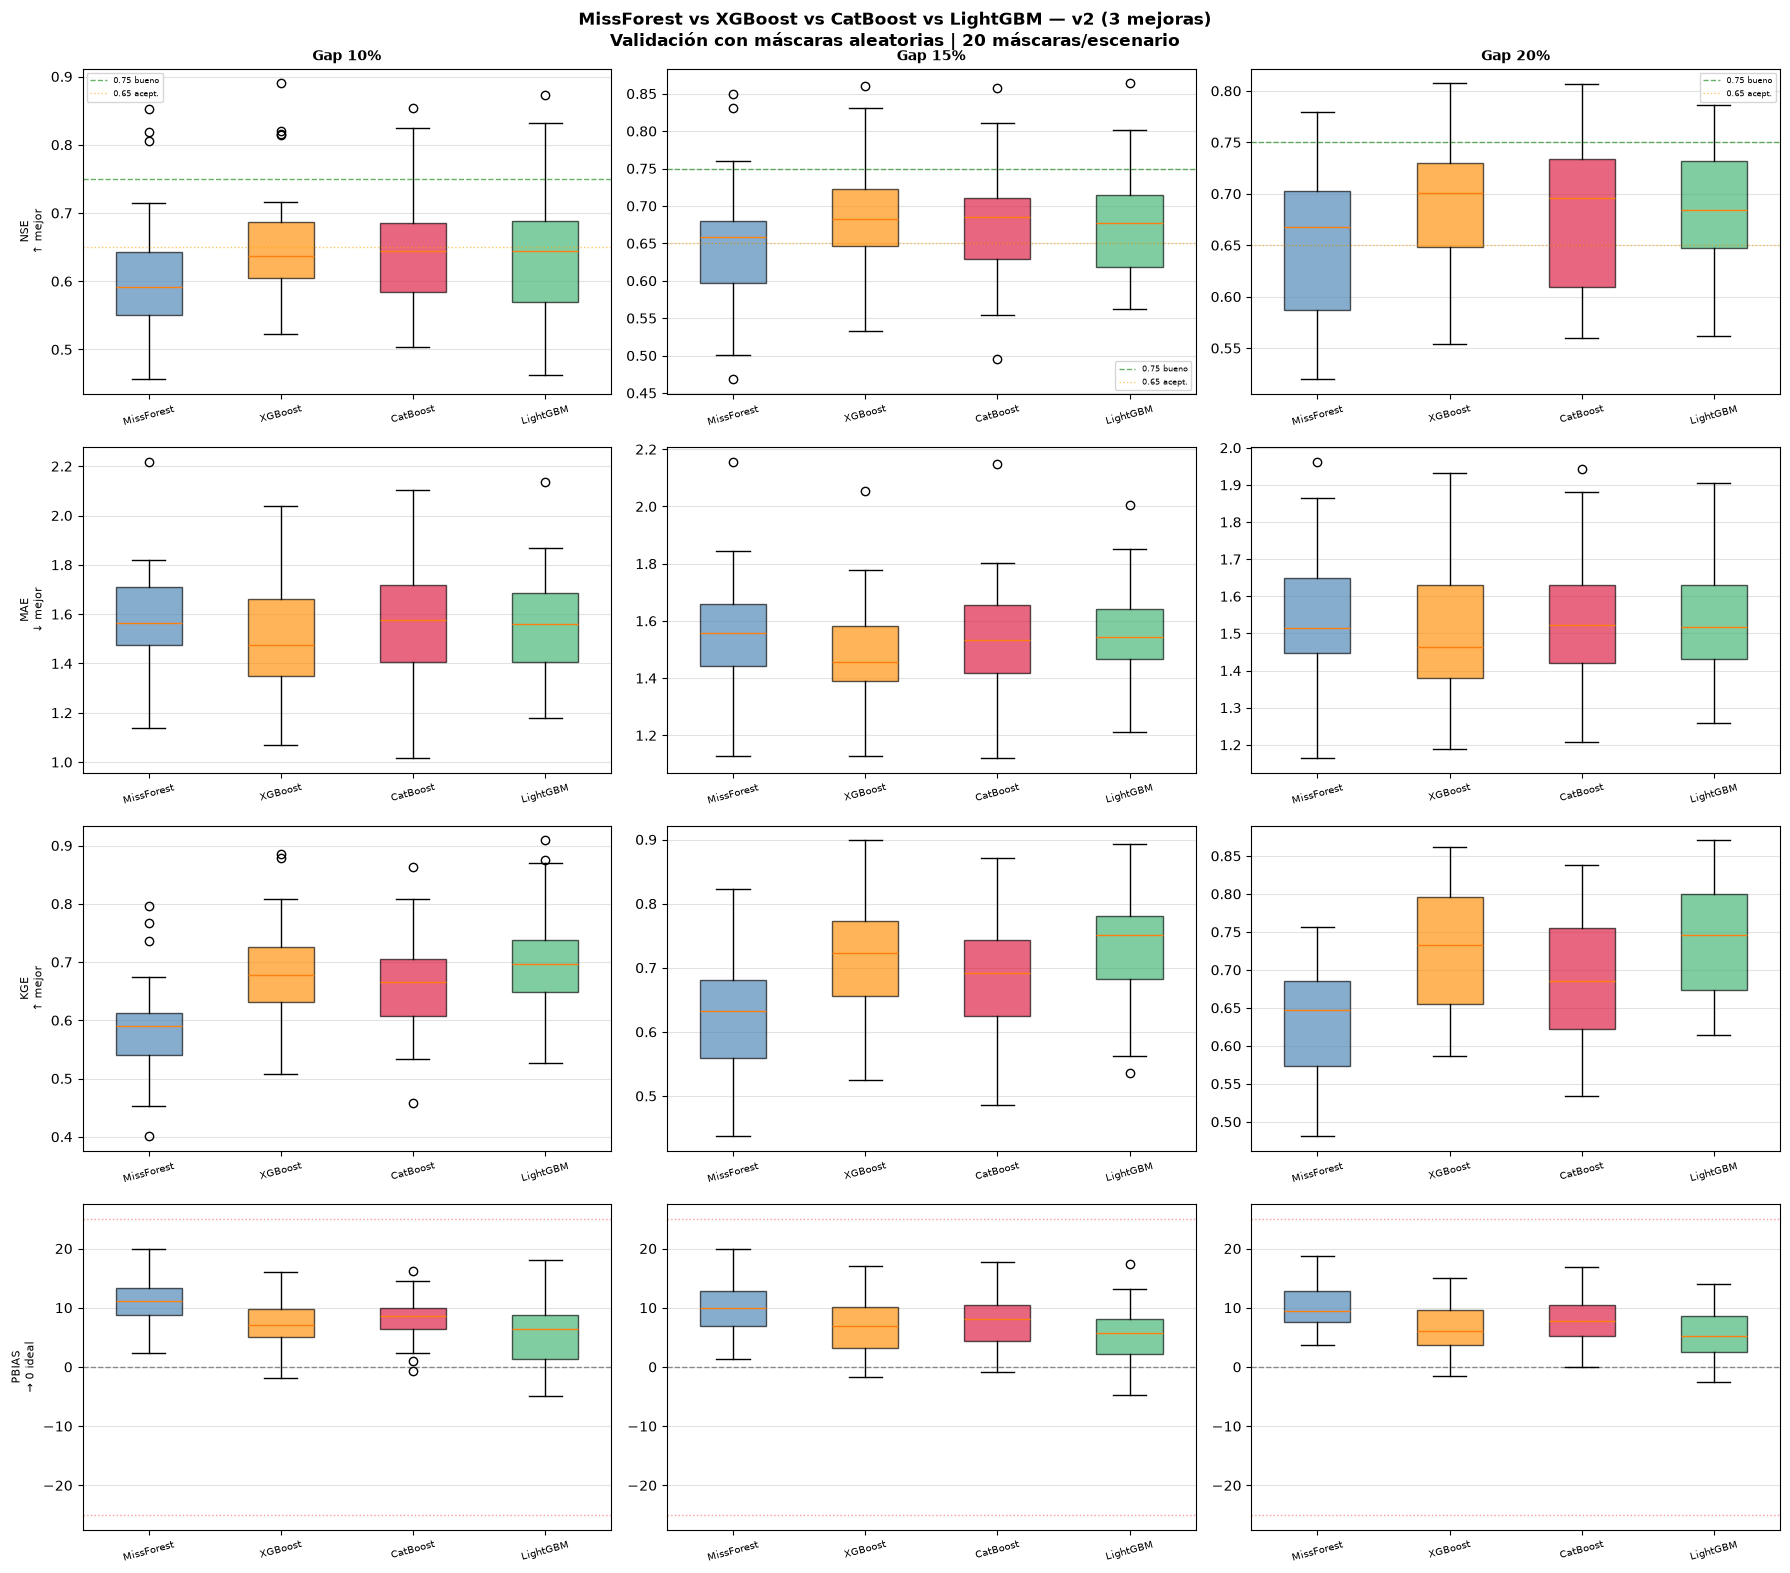

📊 Guardado: metricas_4modelos_v2.png


In [16]:
# ── Figura 1: Distribución de NSE, MAE, KGE y PBIAS por escenario ────────────
colores = {
    'MissForest': 'steelblue',
    'XGBoost':    'darkorange',
    'CatBoost':   'crimson',
    'LightGBM':   'mediumseagreen',   # ← CAMBIO 1
}

pcts       = sorted(df_res['pct_gap'].unique())
metricas_p = ['NSE', 'MAE', 'KGE', 'PBIAS']
fig, axes  = plt.subplots(len(metricas_p), len(pcts),
                          figsize=(18, 16))   # ← CAMBIO 3

for j, pct in enumerate(pcts):
    for i, metrica in enumerate(metricas_p):
        ax = axes[i, j]
        data = [df_res[(df_res['Modelo']==m) &
                       (df_res['pct_gap']==pct)][metrica].values
                for m in colores]
        bp = ax.boxplot(data, tick_labels=list(colores.keys()),
                        patch_artist=True, widths=0.5)
        for patch, color in zip(bp['boxes'], colores.values()):
            patch.set_facecolor(color)
            patch.set_alpha(0.65)
        if metrica == 'NSE':
            ax.axhline(0.75, color='green',  ls='--', lw=1, alpha=0.6,
                       label='0.75 bueno')
            ax.axhline(0.65, color='orange', ls=':',  lw=1, alpha=0.6,
                       label='0.65 acept.')
            ax.legend(fontsize=6)
        if metrica == 'PBIAS':
            ax.axhline(0,   color='black', ls='--', lw=1, alpha=0.4)
            ax.axhline( 25, color='red',   ls=':',  lw=1, alpha=0.4)
            ax.axhline(-25, color='red',   ls=':',  lw=1, alpha=0.4)
        if i == 0:
            ax.set_title(f'Gap {pct}%', fontsize=10, fontweight='bold')
        if j == 0:
            flecha = '↓ mejor' if metrica in ['MAE', 'RMSE'] else '↑ mejor'
            if metrica == 'PBIAS': flecha = '→ 0 ideal'
            ax.set_ylabel(f'{metrica}\n{flecha}', fontsize=8)
        ax.set_xticklabels(list(colores.keys()), fontsize=7, rotation=15)
        ax.grid(axis='y', alpha=0.35)

plt.suptitle(
    'MissForest vs XGBoost vs CatBoost vs LightGBM — v2 (3 mejoras)\n'   # ← CAMBIO 2
    'Validación con máscaras aleatorias | 20 máscaras/escenario',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('metricas_4modelos_v2.png', dpi=150, bbox_inches='tight')   # ← CAMBIO 2
plt.show()
print('📊 Guardado: metricas_4modelos_v2.png')

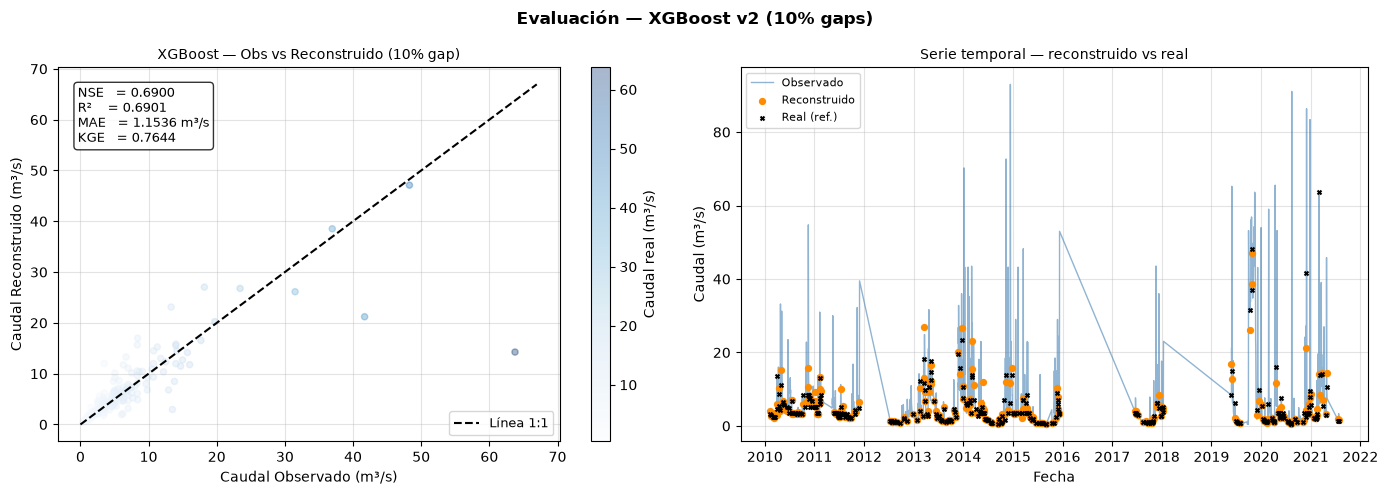

📊 Guardado: scatter_mejor_modelo_v2.png (XGBoost)


In [17]:
# ── Figura 2: Scatter observado vs reconstruido (escenario 10%) ───────────────
# Recrear predicciones con el mejor modelo para el scatter
imputer_scatter = crear_imputer(params_finales[mejor_modelo_nombre])
np.random.seed(42)
mask_sc = np.random.rand(len(df_obs)) < 0.10

df_gap_sc = df_obs.copy()
df_gap_sc.loc[df_gap_sc.index[mask_sc], TARGET] = np.nan

arr_sc = imputer_scatter.fit_transform(df_gap_sc)
df_sc  = pd.DataFrame(arr_sc, columns=df_gap_sc.columns,
                      index=df_gap_sc.index)

y_real = np.expm1(df_obs.loc[df_obs.index[mask_sc], TARGET])
y_pred = np.maximum(np.expm1(df_sc.loc[df_obs.index[mask_sc], TARGET]), 0)

nse_sc  = NSE(y_real, y_pred)
r2_sc   = R2(y_real, y_pred)
mae_sc  = mean_absolute_error(y_real, y_pred)
kge_sc, *_ = he.evaluator(he.kge, y_pred.values, y_real.values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
sc = ax.scatter(y_real, y_pred, alpha=0.35,
                c=y_real, cmap='Blues', s=20)
plt.colorbar(sc, ax=ax, label='Caudal real (m³/s)')
lim = max(y_real.max(), y_pred.max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1.5, label='Línea 1:1')
ax.set_xlabel('Caudal Observado (m³/s)', fontsize=10)
ax.set_ylabel('Caudal Reconstruido (m³/s)', fontsize=10)
ax.set_title(f'{mejor_modelo_nombre} — Obs vs Reconstruido (10% gap)', fontsize=10)
ax.text(0.04, 0.95,
        f'NSE   = {nse_sc:.4f}\n'
        f'R²    = {r2_sc:.4f}\n'
        f'MAE   = {mae_sc:.4f} m³/s\n'
        f'KGE   = {float(kge_sc):.4f}',
        transform=ax.transAxes, fontsize=9, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.legend(fontsize=9)
ax.grid(alpha=0.35)

ax = axes[1]
ax.plot(df_obs.index, np.expm1(df_obs[TARGET]),
        color='steelblue', lw=1.0, alpha=0.6, label='Observado')
ax.scatter(df_obs.index[mask_sc], y_pred,
           color=colores[mejor_modelo_nombre], s=18, zorder=5,
           label='Reconstruido')
ax.scatter(df_obs.index[mask_sc], y_real,
           color='black', s=8, zorder=6, marker='x', label='Real (ref.)')
ax.set_xlabel('Fecha', fontsize=10)
ax.set_ylabel('Caudal (m³/s)', fontsize=10)
ax.set_title('Serie temporal — reconstruido vs real', fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.35)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())

plt.suptitle(f'Evaluación — {mejor_modelo_nombre} v2 (10% gaps)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('scatter_mejor_modelo_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'📊 Guardado: scatter_mejor_modelo_v2.png ({mejor_modelo_nombre})')

## 🏗️ PASO 8 — Reconstrucción final

Solo se reconstruyen gaps ≤ 30 días. Los gaps más largos
se marcan explícitamente como `'No reconstruido'`.
El modelo final usa parámetros completos para máxima precisión.

In [18]:
# ── Identificar gaps ≤ 100 días ────────────────────────────────────────────────
UMBRAL = 400

def get_mask_gaps_cortos(serie, umbral=400):
    """Retorna máscara booleana de días que pertenecen a gaps ≤ umbral días."""
    mask = pd.Series(False, index=serie.index)
    en_gap, inicio = False, None

    for fecha, valor in serie.items():
        if pd.isna(valor):
            if not en_gap:
                inicio = fecha
                en_gap = True
        else:
            if en_gap:
                dur = (fecha - inicio).days
                if dur <= umbral:
                    mask[inicio:fecha] = True
                en_gap = False

    if en_gap:  # gap al final
        dur = (serie.index[-1] - inicio).days
        if dur <= umbral:
            mask[inicio:] = True

    return mask


serie_full     = df_full[TARGET]
mask_gc        = get_mask_gaps_cortos(serie_full, UMBRAL)
mask_faltante  = serie_full.isna()
mask_recons    = mask_gc & mask_faltante
mask_no_recons = ~mask_gc & mask_faltante

print(f'Gaps ≤ {UMBRAL} días — días a reconstruir: {mask_recons.sum()}')
print(f'Gaps > {UMBRAL} días — días excluidos    : {mask_no_recons.sum()}')

# Dataset de reconstrucción: observados + gaps cortos únicamente
mask_usar   = ~mask_faltante | mask_recons
df_para_rec = df_full[mask_usar].copy()

print(f'\nFilas en dataset de reconstrucción: {len(df_para_rec)}')
print(f'  Observadas : {df_para_rec[TARGET].notna().sum()}')
print(f'  A rellenar : {df_para_rec[TARGET].isna().sum()}')

Gaps ≤ 400 días — días a reconstruir: 589
Gaps > 400 días — días excluidos    : 1052

Filas en dataset de reconstrucción: 3284
  Observadas : 2695
  A rellenar : 589


In [19]:
print(f'🚀 Reconstruyendo con {mejor_modelo_nombre} — parámetros completos...')
print('   max_iter=10 — ~3-5 minutos\n')

imputer_final = crear_imputer(params_finales[mejor_modelo_nombre], max_iter=10)
arr_final     = imputer_final.fit_transform(df_para_rec)

df_rec_temp   = pd.DataFrame(arr_final,
                             columns=df_para_rec.columns,
                             index=df_para_rec.index)

# Ensamblar serie final
df_final = df_full[[TARGET]].copy()
df_final.loc[mask_recons, TARGET] = \
    df_rec_temp.loc[mask_recons[mask_usar], TARGET].values

# Convertir de log a m³/s
df_final['Caudal_m3s'] = np.maximum(np.expm1(df_final[TARGET]), 0)

# Etiquetas de fuente
fuente = pd.Series('Observado', index=df_final.index)
fuente[mask_recons]    = f'Reconstruido ({mejor_modelo_nombre} v2 ≤{UMBRAL}d)'
fuente[mask_no_recons] = f'No reconstruido (gap >{UMBRAL}d)'
df_final['Fuente'] = fuente

print('\n📋 Resultado final:')
for src, cnt in df_final['Fuente'].value_counts().items():
    print(f'  {src}: {cnt} días')

🚀 Reconstruyendo con XGBoost — parámetros completos...
   max_iter=10 — ~3-5 minutos


📋 Resultado final:
  Observado: 2695 días
  No reconstruido (gap >400d): 1052 días
  Reconstruido (XGBoost v2 ≤400d): 589 días


In [20]:
# ── Visualización interactiva ─────────────────────────────────────────────────
obs_s  = df_final[df_final['Fuente'] == 'Observado']
rec_s  = df_final[df_final['Fuente'].str.contains('Reconstruido \(')]
nrec_s = df_final[df_final['Fuente'].str.contains('No reconstruido')]

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=obs_s.index, y=obs_s['Caudal_m3s'],
    mode='lines', name='Observado',
    line=dict(color='steelblue', width=1.5)
))
fig.add_trace(go.Scatter(
    x=rec_s.index, y=rec_s['Caudal_m3s'],
    mode='markers', name=f'Reconstruido (≤{UMBRAL}d)',
    marker=dict(color='green', size=5)
))
if len(nrec_s) > 0:
    fig.add_trace(go.Scatter(
        x=nrec_s.index, y=[0]*len(nrec_s),
        mode='markers', name=f'No reconstruido (>{UMBRAL}d)',
        marker=dict(color='tomato', size=3, symbol='x')
    ))

fig.update_layout(
    title=f'Serie de Caudal Reconstruida — Santander | CatBoost v2',
    xaxis_title='Fecha', yaxis_title='Caudal (m³/s)',
    hovermode='x unified', height=430,
    legend=dict(x=0, y=1.12, orientation='h')
)
fig.show()

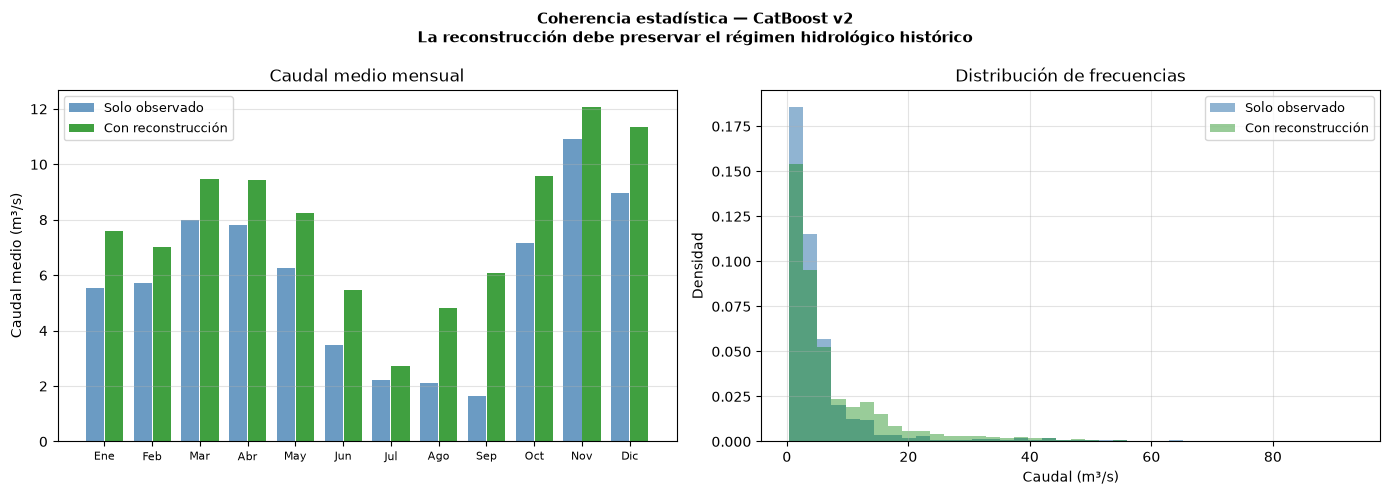

📊 Guardado: coherencia_estadistica_v2.png


In [21]:
# ── Coherencia estadística: distribución mensual ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

meses_nom = ['Ene','Feb','Mar','Abr','May','Jun',
              'Jul','Ago','Sep','Oct','Nov','Dic']

# Media mensual
ax = axes[0]
df_validos = df_final[df_final['Fuente'] != f'No reconstruido (gap >{UMBRAL}d)']
med_obs  = obs_s['Caudal_m3s'].groupby(obs_s.index.month).mean()
med_full = df_validos['Caudal_m3s'].groupby(df_validos.index.month).mean()

x = np.arange(12)
ax.bar(x-0.2, med_obs.reindex(range(1,13), fill_value=0),
       0.38, label='Solo observado', color='steelblue', alpha=0.8)
ax.bar(x+0.2, med_full.reindex(range(1,13), fill_value=0),
       0.38, label='Con reconstrucción', color='green', alpha=0.75)
ax.set_xticks(x)
ax.set_xticklabels(meses_nom, fontsize=8)
ax.set_ylabel('Caudal medio (m³/s)')
ax.set_title('Caudal medio mensual')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.35)

# Distribución de frecuencias
ax = axes[1]
ax.hist(obs_s['Caudal_m3s'].dropna(), bins=40,
        alpha=0.6, color='steelblue',
        label='Solo observado', density=True)
ax.hist(df_validos['Caudal_m3s'].dropna(), bins=40,
        alpha=0.4, color='green',
        label='Con reconstrucción', density=True)
ax.set_xlabel('Caudal (m³/s)')
ax.set_ylabel('Densidad')
ax.set_title('Distribución de frecuencias')
ax.legend(fontsize=9)
ax.grid(alpha=0.35)

plt.suptitle(
    'Coherencia estadística — CatBoost v2\n'
    'La reconstrucción debe preservar el régimen hidrológico histórico',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig('coherencia_estadistica_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Guardado: coherencia_estadistica_v2.png')

## 💾 PASO 9 — Exportar resultados

In [22]:
# ── Serie reconstruida ────────────────────────────────────────────────────────
nombre_arch = mejor_modelo_nombre.replace(' ', '_')
df_final[['Caudal_m3s', 'Fuente']].rename_axis('Fecha').to_excel(
    f'Buga_caudal_reconstruido_{nombre_arch}_v2.xlsx'
)

# ── Métricas de validación ────────────────────────────────────────────────────
df_res.to_excel('validacion_3modelos_v2_detallado.xlsx', index=False)

# ── Resumen final ─────────────────────────────────────────────────────────────
print('\n' + '='*65)
print('📋 RESUMEN FINAL — 3 Modelos v2 (con mejoras)')
print('='*65)

print('\n  Mejoras aplicadas a los 3 modelos:')
print('    1. Leads de caudal     : Q_lead1..Q_lead15')
print('    2. Estacionalidad cíclica: mes_sin, mes_cos, dia_sin, dia_cos')
print('    3. Precipitación máxima: P_max7d')

print('\n  Rendimiento en validación (NSE medio):')
print(f'  {"Modelo":12s} | {"10% gap":>8} | {"15% gap":>8} | {"20% gap":>8}')
print(f'  {"-"*12}-+-{"─"*8}-+-{"─"*8}-+-{"─"*8}')
for modelo in ['MissForest', 'XGBoost', 'CatBoost']:
    vals = [df_res[(df_res['Modelo']==modelo)&
                   (df_res['pct_gap']==p)]['NSE'].mean()
            for p in [10,15,20]]
    marca = ' 🏆' if modelo == mejor_modelo_nombre else ''
    print(f'  {modelo:12s} | {vals[0]:>8.4f} | {vals[1]:>8.4f} | {vals[2]:>8.4f}{marca}')

print(f'\n  Mejor modelo: 🏆 {mejor_modelo_nombre}')

print('\n  Datos reconstruidos:')
for src, cnt in df_final['Fuente'].value_counts().items():
    print(f'    {src}: {cnt} días')

print('\n  Archivos generados:')
for f in [f'Buga_caudal_reconstruido_{nombre_arch}_v2.xlsx',
          'validacion_3modelos_v2_detallado.xlsx',
          'metricas_3modelos_v2.xlsx']:
    print(f'    → {f}')
print('='*65)


📋 RESUMEN FINAL — 3 Modelos v2 (con mejoras)

  Mejoras aplicadas a los 3 modelos:
    1. Leads de caudal     : Q_lead1..Q_lead15
    2. Estacionalidad cíclica: mes_sin, mes_cos, dia_sin, dia_cos
    3. Precipitación máxima: P_max7d

  Rendimiento en validación (NSE medio):
  Modelo       |  10% gap |  15% gap |  20% gap
  -------------+-────────-+-────────-+-────────
  MissForest   |   0.6141 |   0.6501 |   0.6506
  XGBoost      |   0.6643 |   0.6901 |   0.6901 🏆
  CatBoost     |   0.6518 |   0.6779 |   0.6813

  Mejor modelo: 🏆 XGBoost

  Datos reconstruidos:
    Observado: 2695 días
    No reconstruido (gap >400d): 1052 días
    Reconstruido (XGBoost v2 ≤400d): 589 días

  Archivos generados:
    → Buga_caudal_reconstruido_XGBoost_v2.xlsx
    → validacion_3modelos_v2_detallado.xlsx
    → metricas_3modelos_v2.xlsx
